In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# TAHAP 1: DATA COLLECTION
df = pd.read_csv('loan_approval.csv')

print("--- 5 Baris Pertama Dataset ---")
print(df.head())
print(f"\nUkuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

--- 5 Baris Pertama Dataset ---
              name              city  income  credit_score  loan_amount  \
0     Allison Hill         East Jill  113810           389        39698   
1     Brandon Hall     New Jamesside   44592           729        15446   
2     Rhonda Smith      Lake Roberto   33278           584        11189   
3  Gabrielle Davis  West Melanieview  127196           344        48823   
4     Valerie Gray         Mariastad   66048           496        47174   

   years_employed  points  loan_approved  
0              27    50.0          False  
1              28    55.0          False  
2              13    45.0          False  
3              29    50.0          False  
4               4    25.0          False  

Ukuran Dataset: 2000 baris, 8 kolom


In [2]:
# TAHAP 2: DATA PREPROCESSING
# Hapus kolom identitas teks ('name', 'city') yang tidak digunakan
X = df.drop(columns=['name', 'city', 'loan_approved'])

# Ubah target/label 'loan_approved' (True/False) menjadi angka (1/0)
y = df['loan_approved'].astype(int)

# Normalisasi nilai fitur numerik menggunakan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Pra-pemrosesan data berhasil: Kolom teks dihapus dan data numerik telah diskalakan.")

Pra-pemrosesan data berhasil: Kolom teks dihapus dan data numerik telah diskalakan.


In [3]:
# TAHAP 3: DATA SPLITTING
# Membagi 80% data latih dan 20% data uji
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data Latih (Training) : {X_train.shape[0]} sampel")
print(f"Data Uji (Testing)   : {X_test.shape[0]} sampel")

Data Latih (Training) : 1600 sampel
Data Uji (Testing)   : 400 sampel


In [4]:
# TAHAP 4: MODEL TRAINING
# Inisialisasi 3 algoritma klasifikasi
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

print("Seluruh model berhasil dilatih!")

Seluruh model berhasil dilatih!


--- Perbandingan Hasil Evaluasi Model ---
              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression       1.0        1.0     1.0       1.0
      Decision Tree       1.0        1.0     1.0       1.0
      Random Forest       1.0        1.0     1.0       1.0


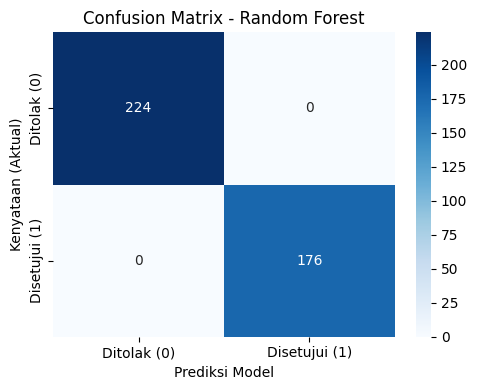

In [5]:
# TAHAP 5: MODEL EVALUATION
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

df_results = pd.DataFrame(results)
print("--- Perbandingan Hasil Evaluasi Model ---")
print(df_results.to_string(index=False))

# Visualisasi Confusion Matrix untuk Random Forest
best_model = trained_models["Random Forest"]
y_pred_rf = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Ditolak (0)', 'Disetujui (1)'],
            yticklabels=['Ditolak (0)', 'Disetujui (1)'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi Model')
plt.ylabel('Kenyataan (Aktual)')
plt.tight_layout()
plt.show()

In [8]:
# TAHAP 6: INFERENCE
# Memasukkan data nasabah baru lengkap dengan nama kolomnya
nasabah_baru = pd.DataFrame(
    [[85000, 720, 20000, 5, 75.0]],
    columns=X.columns
)

# Skalakan data baru dengan scaler yang telah dilatih
nasabah_baru_scaled = scaler.transform(nasabah_baru)

# Prediksi menggunakan model Random Forest
prediksi = best_model.predict(nasabah_baru_scaled)
probabilitas = best_model.predict_proba(nasabah_baru_scaled)

status = "DISETUJUI (APPROVED)" if prediksi[0] == 1 else "DITOLAK (REJECTED)"
print("--- Hasil Inferensi Nasabah Baru ---")
print(f"Status Pengajuan : {status}")
print(f"Probabilitas     : {probabilitas[0][1]*100:.2f}%")

--- Hasil Inferensi Nasabah Baru ---
Status Pengajuan : DISETUJUI (APPROVED)
Probabilitas     : 100.00%
